-> Training FD001...
   Dataset FD001: RMSE = 17.21 | R2 = 0.8155
-> Training FD002...
   Dataset FD002: RMSE = 17.98 | R2 = 0.8247
-> Training FD003...
   Dataset FD003: RMSE = 20.08 | R2 = 0.7373
-> Training FD004...
   Dataset FD004: RMSE = 20.28 | R2 = 0.7775

--- FINAL SUMMARY (MEMBER 2 - RANDOM FOREST) ---


,Dataset,RMSE,R2_Score,Num_Features
0,FD001,17.211834,0.815522,21
1,FD002,17.979298,0.824678,24
2,FD003,20.076036,0.737254,21
3,FD004,20.275589,0.777469,24


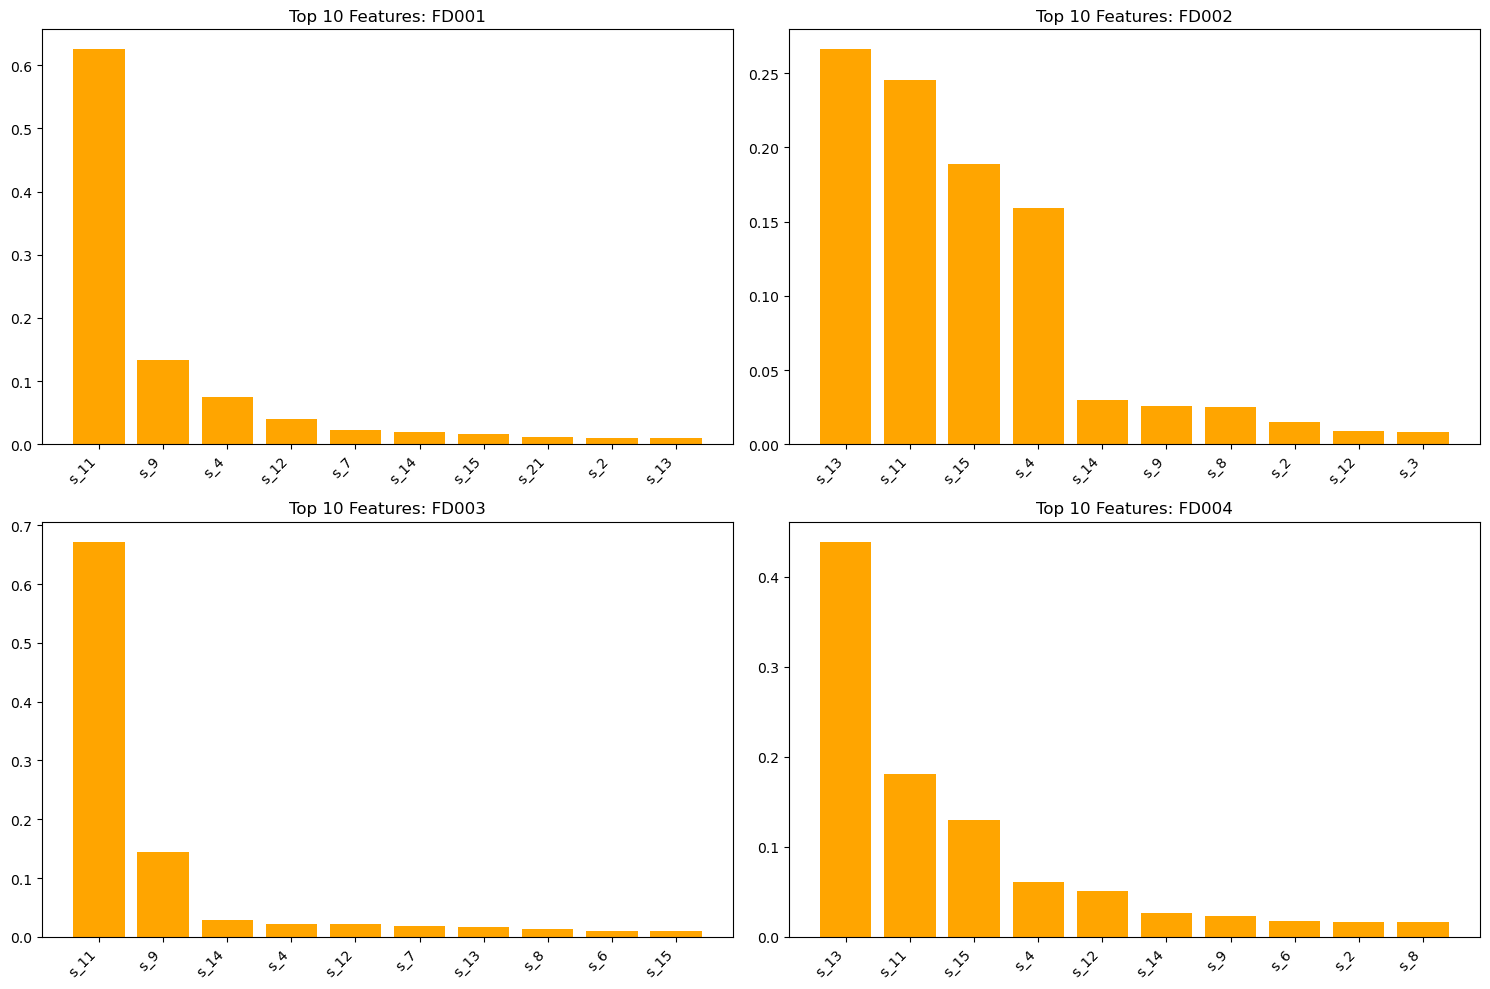

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

datasets = ['FD001', 'FD002', 'FD003', 'FD004']
results_rf = []
plot_data = []

for file_id in datasets:
    
    try:
        train_path = f'../data/processed/train_{file_id}_processed.csv'
        test_path = f'../data/processed/test_{file_id}_processed.csv'
        rul_path = f'../data/raw/RUL_{file_id}.txt'

        df_train = pd.read_csv(train_path)
        df_test = pd.read_csv(test_path)
        df_rul = pd.read_csv(rul_path, header=None, names=['RUL_actual'])
    except FileNotFoundError:
        print(f"Error: Data not found for {file_id}. Skipping.")
        continue

    df_train['RUL'] = df_train['RUL'].clip(upper=125)
    y_true = df_rul['RUL_actual'].clip(upper=125)

    features = [col for col in df_train.columns if col not in ['unit_nr', 'time_cycles', 'RUL']]
    X_train = df_train[features]
    y_train = df_train['RUL']

    model = RandomForestRegressor(n_estimators=100, max_depth=12, random_state=42, n_jobs=-1)
    
    print(f"-> Training {file_id}...")
    model.fit(X_train, y_train)

    test_last_cycle = df_test.groupby('unit_nr').last().reset_index()
    X_test = test_last_cycle[features]
    y_pred = model.predict(X_test)

    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    
    results_rf.append({
        'Dataset': file_id, 
        'RMSE': rmse, 
        'R2_Score': r2,
        'Num_Features': len(features)
    })
    
    print(f"   Dataset {file_id}: RMSE = {rmse:.2f} | R2 = {r2:.4f}")

    importances = model.feature_importances_
    indices = np.argsort(importances)[::-1][:10]
    
    
    plot_data.append({
        'id': file_id,
        'importances': importances[indices],
        'feature_names': [features[i] for i in indices]
    })

results_df = pd.DataFrame(results_rf)
print("\n--- FINAL SUMMARY (MEMBER 2 - RANDOM FOREST) ---")
try:
    display(results_df)
except:
    print(results_df)

if plot_data:
  
    fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(15, 10))
    axes = axes.flatten()

    for i, data in enumerate(plot_data):
        ax = axes[i]
        ax.bar(range(10), data['importances'], align="center", color='orange')
        ax.set_xticks(range(10))
        ax.set_xticklabels(data['feature_names'], rotation=45, ha="right")
        ax.set_title(f"Top 10 Features: {data['id']}")

    plt.tight_layout()
    plt.show()